# Retraso en la salida de vuelos (`DepDel15`) — EDA y filtrado de fuga de información

**Dataset:** BTS Reporting Carrier On-Time Performance, 2022–2026 (~32,4 M de filas, 35 columnas, ~10,5 GB en pandas)
**Objetivo de este notebook (entregable de la semana):**

1. Análisis Exploratorio de Datos (calidad de datos, comportamiento del objetivo, patrones de retraso por calendario / horario / aerolínea / aeropuerto / ruta / distancia, correlaciones).
2. Auditoría y filtrado de fuga de información (*information leakage*): decidir, columna por columna, qué **no se conoce al momento de la predicción** (antes de la salida), respaldar esa decisión con evidencia empírica y exportar un parquet limpio.

**Cómo maneja 32 M de filas:** todas las agregaciones pesadas se ejecutan **dentro de DuckDB directamente sobre el archivo parquet** (nada cercano a 10 GB se carga en pandas). Solo se trae a pandas una muestra aleatoria de 1 M de filas para las pruebas a nivel de fila (distribuciones, correlaciones, AUC de una sola variable). El dataset limpio final se escribe con un `COPY` en streaming, de nuevo sin cargarlo en memoria.

**Supuesto del momento de predicción:** el modelo predice, *antes de que el vuelo salga*, si despegará con 15 o más minutos de retraso. Todo lo que solo se observa en el pushback o después es fuga.

| Sección | Qué hace |
|---|---|
| 0 | Configuración, imports, estilo de gráficos |
| 1 | Carga perezosa (lazy) del parquet (vistas de DuckDB) |
| 2 | Calidad de datos: valores faltantes, cobertura de fechas, duplicados, consistencia |
| 3 | Análisis del objetivo: balance, nulos, deriva en el tiempo |
| 4 | EDA de variables previas a la salida (32 M de filas completas) |
| 5 | Muestra de 1 M de filas para análisis a nivel de fila |
| 6 | **Auditoría de fuga** (regla de la línea de tiempo + pruebas empíricas + tabla de decisiones) |
| 7 | **Filtrado y exportación** del parquet limpio |

## 0. Configuración

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [ ]:
PARQUET_PATH = "bts_2022_2026.parquet"
OUT_DIR      = Path("outputs_eda")
TARGET       = "DepDel15"

MEMORY_LIMIT = "8GB"
TEMP_DIR     = "duckdb_tmp"

SAMPLE_ROWS  = 1_000_000
SEED         = 42

MIN_AIRPORT_FLIGHTS = 20_000
MIN_ROUTE_FLIGHTS   = 5_000
SUSPICIOUS_AUC      = 0.80
DROP_DIVERTED_ROWS  = False

OUT_DIR = Path(OUT_DIR)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
Path(TEMP_DIR).mkdir(exist_ok=True)

In [7]:
# Estilo de gráficos: un color de acento para "lo que se mide", naranja solo para "alerta / fuga / retraso".
ACCENT, ALERT, MUTED = "#2a6fb0", "#c8571b", "#8a8f98"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8bcc2", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e8eb", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

def q(sql):
    """Ejecuta SQL en DuckDB y devuelve un DataFrame de pandas."""
    return con.sql(sql).df()

def rate_by(expr, where="1=1", min_n=1, order_by="1"):
    """Vuelos y tasa de retraso agrupados por una expresión SQL (dataset completo, objetivo no nulo)."""
    return q(f"""
        SELECT {expr} AS grp, COUNT(*) AS n, AVG({TARGET}) AS delay_rate
        FROM flights
        WHERE {TARGET} IS NOT NULL AND {where}
        GROUP BY 1
        HAVING COUNT(*) >= {min_n}
        ORDER BY {order_by}
    """)

def bar_rate(d, ax, title, rot=0, x="grp"):
    ax.bar(d[x].astype(str), d["delay_rate"] * 100, color=ACCENT, width=0.72)
    ax.axhline(BASE_RATE * 100, color=MUTED, lw=1, ls="--")
    ax.set_title(title)
    ax.set_ylabel("% con retraso ≥15 min")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=rot)

## 1. Carga (perezosa, vía DuckDB)

Se crean dos vistas: `flights_raw` (el archivo tal cual) y `flights` (los mismos datos, pero con `NaN` → `NULL` en las columnas float para que el conteo de faltantes sea confiable, y `FlightDate` convertida a un `DATE` real). Todavía no se lee nada en memoria.

In [8]:
con = duckdb.connect()
con.execute(f"SET memory_limit='{MEMORY_LIMIT}'")
con.execute(f"SET temp_directory='{TEMP_DIR}'")

con.execute(f"CREATE OR REPLACE VIEW flights_raw AS SELECT * FROM read_parquet('{PARQUET_PATH}')")

raw_schema = con.sql("DESCRIBE flights_raw").df()[["column_name", "column_type"]]
float_cols = raw_schema.loc[raw_schema.column_type.isin(["DOUBLE", "FLOAT"]), "column_name"].tolist()

replacements = [f'CASE WHEN isnan("{c}") THEN NULL ELSE "{c}" END AS "{c}"' for c in float_cols]
replacements.append('CAST("FlightDate" AS DATE) AS "FlightDate"')
con.execute(f"CREATE OR REPLACE VIEW flights AS SELECT * REPLACE ({', '.join(replacements)}) FROM flights_raw")

N = con.sql("SELECT COUNT(*) FROM flights").fetchall()[0][0]
ALL_COLS = con.sql("DESCRIBE flights").df()["column_name"].tolist()
print(f"Rows: {N:,} | Columns: {len(ALL_COLS)}")
raw_schema

Rows: 32,386,436 | Columns: 35


,column_name,column_type
0,DepDel15,DOUBLE
1,FlightDate,DATE
2,Year,BIGINT
3,Reporting_Airline,VARCHAR
4,Quarter,BIGINT
5,Month,BIGINT
6,DayofMonth,BIGINT
7,DayOfWeek,BIGINT
8,Origin,VARCHAR
9,Dest,VARCHAR


In [9]:
q("SELECT * FROM flights LIMIT 5")

,DepDel15,FlightDate,Year,Reporting_Airline,Quarter,Month,DayofMonth,DayOfWeek,Origin,Dest,OriginState,DestState,CRSDepTime,DepTimeBlk,CRSArrTime,CRSElapsedTime,Distance,Flight_Number_Reporting_Airline,Tail_Number,Cancelled,CancellationCode,Diverted,DepTime,DepDelay,DepDelayMinutes,DepartureDelayGroups,TaxiOut,WheelsOff,ArrDelay,ArrDel15,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,0.0000,2022-01-14,2022,YX,1,1,14,5,CMH,DCA,OH,VA,1224,1200-1259,1352,88.0000,323.0000,4879,N119HQ,0.0000,None,0.0000,"1,221.0000",-3.0000,0.0000,-1.0000,28.0000,"1,249.0000",4.0000,0.0000,NaN,NaN,NaN,NaN,NaN
1,0.0000,2022-01-15,2022,YX,1,1,15,6,CMH,DCA,OH,VA,1224,1200-1259,1352,88.0000,323.0000,4879,N122HQ,0.0000,None,0.0000,"1,214.0000",-10.0000,0.0000,-1.0000,19.0000,"1,233.0000",-24.0000,0.0000,NaN,NaN,NaN,NaN,NaN
2,0.0000,2022-01-16,2022,YX,1,1,16,7,CMH,DCA,OH,VA,1224,1200-1259,1352,88.0000,323.0000,4879,N412YX,0.0000,None,0.0000,"1,218.0000",-6.0000,0.0000,-1.0000,16.0000,"1,234.0000",-13.0000,0.0000,NaN,NaN,NaN,NaN,NaN
3,0.0000,2022-01-17,2022,YX,1,1,17,1,CMH,DCA,OH,VA,1224,1200-1259,1352,88.0000,323.0000,4879,N405YX,0.0000,None,0.0000,"1,217.0000",-7.0000,0.0000,-1.0000,32.0000,"1,249.0000",9.0000,0.0000,NaN,NaN,NaN,NaN,NaN
4,0.0000,2022-01-18,2022,YX,1,1,18,2,CMH,DCA,OH,VA,1224,1200-1259,1352,88.0000,323.0000,4879,N420YX,0.0000,None,0.0000,"1,218.0000",-6.0000,0.0000,-1.0000,11.0000,"1,229.0000",-29.0000,0.0000,NaN,NaN,NaN,NaN,NaN


## 2. Calidad de datos

,dtype,missing,pct_missing
CancellationCode,VARCHAR,31814091,98.2328
LateAircraftDelay,DOUBLE,25552520,78.8988
CarrierDelay,DOUBLE,25552520,78.8988
NASDelay,DOUBLE,25552520,78.8988
WeatherDelay,DOUBLE,25552520,78.8988
SecurityDelay,DOUBLE,25552520,78.8988
ArrDel15,DOUBLE,657424,2.0299
ArrDelay,DOUBLE,657424,2.0299
WheelsOff,DOUBLE,569139,1.7573
TaxiOut,DOUBLE,569139,1.7573


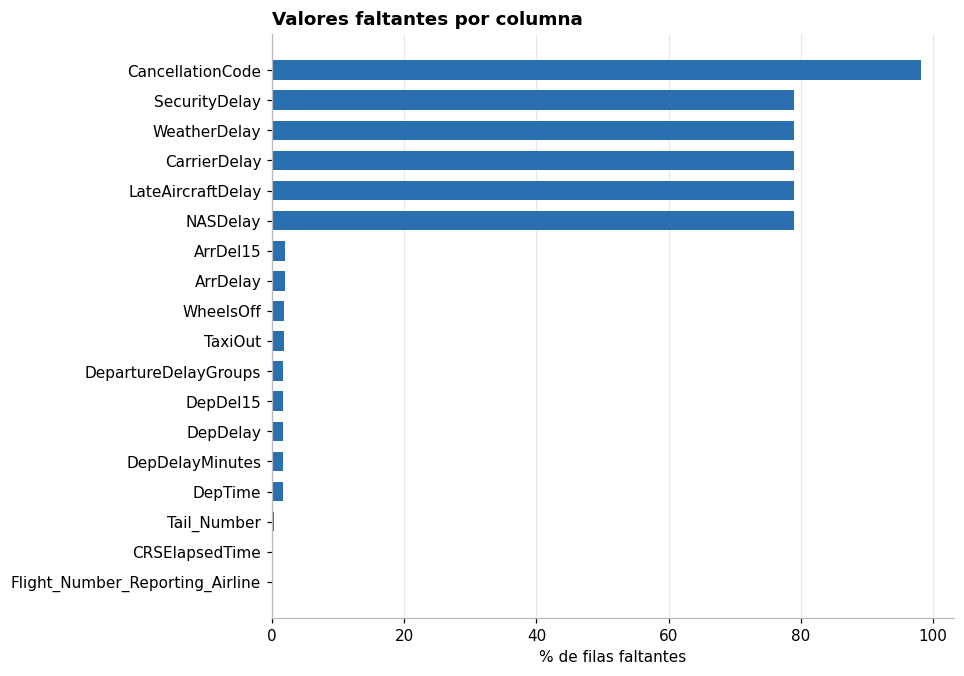

In [10]:
# 2.1 Valores faltantes por columna (dataset completo)
col_types = dict(zip(raw_schema.column_name, raw_schema.column_type))
sel = ", ".join(f'COUNT(*) - COUNT("{c}") AS "{c}"' for c in ALL_COLS)
miss = q(f"SELECT {sel} FROM flights").iloc[0]
miss_df = pd.DataFrame({"dtype": pd.Series(col_types), "missing": miss, "pct_missing": miss / N * 100})
miss_df = miss_df.sort_values("pct_missing", ascending=False)
display(miss_df)

shown = miss_df[miss_df.pct_missing > 0].sort_values("pct_missing")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(shown) + 1.5))
ax.barh(shown.index, shown.pct_missing, color=ACCENT, height=0.65)
ax.set_xlabel("% de filas faltantes"); ax.set_title("Valores faltantes por columna")
ax.grid(axis="y", visible=False)
savefig(fig, "02_missing_values")

Rango de fechas: 2022-01-01 → 2026-08-01 | meses: 56


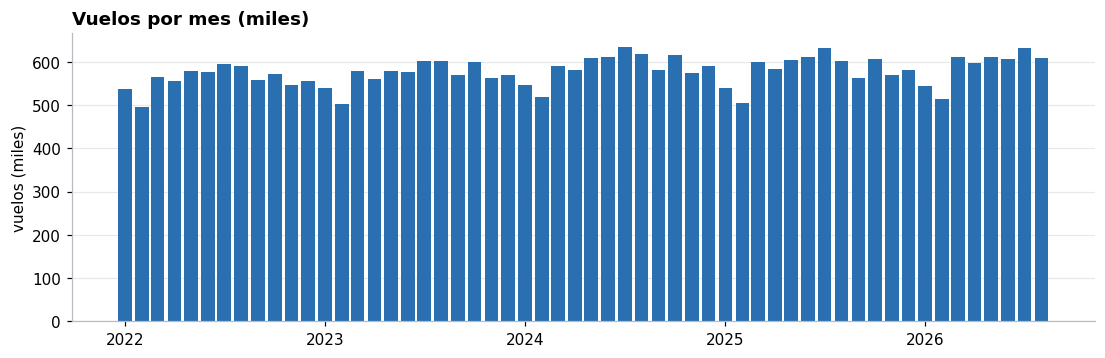

In [11]:
# 2.2 Cobertura de fechas: filas por mes (los huecos o meses parciales se notan de inmediato)
cov = q("""
    SELECT date_trunc('month', FlightDate)::DATE AS month, COUNT(*) AS flights
    FROM flights GROUP BY 1 ORDER BY 1
""")
print("Rango de fechas:", cov.month.min().date(), "→", cov.month.max().date(), "| meses:", len(cov))

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(cov.month, cov.flights / 1e3, width=25, color=ACCENT)
ax.set_title("Vuelos por mes (miles)"); ax.set_ylabel("vuelos (miles)")
ax.grid(axis="x", visible=False)
savefig(fig, "02_rows_per_month")

In [12]:
# 2.3 Duplicados y verificaciones de consistencia (dataset completo)
dups = q("""
    SELECT COALESCE(SUM(c - 1), 0) AS duplicate_rows FROM (
        SELECT COUNT(*) AS c FROM flights
        GROUP BY FlightDate, Reporting_Airline, Flight_Number_Reporting_Airline, Origin, Dest, CRSDepTime
        HAVING COUNT(*) > 1)
""").iloc[0, 0]
print(f"Filas que comparten (fecha, aerolínea, n.º de vuelo, origen, destino, salida programada): {int(dups):,}")

checks = q(f"""
    SELECT
      SUM(CASE WHEN Year <> year(FlightDate) THEN 1 ELSE 0 END)           AS year_vs_date,
      SUM(CASE WHEN Quarter <> quarter(FlightDate) THEN 1 ELSE 0 END)     AS quarter_vs_date,
      SUM(CASE WHEN Month <> month(FlightDate) THEN 1 ELSE 0 END)         AS month_vs_date,
      SUM(CASE WHEN DayofMonth <> day(FlightDate) THEN 1 ELSE 0 END)      AS day_vs_date,
      SUM(CASE WHEN DayOfWeek <> isodow(FlightDate) THEN 1 ELSE 0 END)    AS dow_vs_date,
      SUM(CASE WHEN Origin = Dest THEN 1 ELSE 0 END)                      AS origin_equals_dest,
      SUM(CASE WHEN Distance <= 0 THEN 1 ELSE 0 END)                      AS nonpositive_distance,
      SUM(CASE WHEN CRSElapsedTime <= 0 THEN 1 ELSE 0 END)                AS nonpositive_sched_elapsed,
      SUM(CASE WHEN CRSDepTime < 0 OR CRSDepTime > 2400 THEN 1 ELSE 0 END) AS sched_dep_out_of_range,
      SUM(CASE WHEN {TARGET} NOT IN (0, 1) THEN 1 ELSE 0 END)             AS target_not_binary
    FROM flights
""").iloc[0]
checks.to_frame("rows_violating").rename_axis("check")

Filas que comparten (fecha, aerolínea, n.º de vuelo, origen, destino, salida programada): 0


,rows_violating
check,
year_vs_date,0.0000
quarter_vs_date,0.0000
month_vs_date,0.0000
day_vs_date,0.0000
dow_vs_date,0.0000
origin_equals_dest,0.0000
nonpositive_distance,0.0000
nonpositive_sched_elapsed,21.0000
sched_dep_out_of_range,0.0000


## 3. Análisis del objetivo

`DepDel15` es nulo cuando el vuelo no tiene un retraso de salida registrado (principalmente vuelos cancelados). Esas filas no sirven para entrenamiento supervisado y se eliminan en la exportación (sección 7). Aquí verificamos exactamente de dónde vienen los nulos.

,target,Cancelled,Diverted,n,pct
0,0.0000,0.0000,0.0000,24927593,76.9692
1,1.0000,0.0000,0.0000,6801422,21.0008
2,NaN,1.0000,0.0000,553405,1.7088
3,0.0000,0.0000,1.0000,53995,0.1667
4,1.0000,0.0000,1.0000,31081,0.0960
5,1.0000,1.0000,0.0000,11454,0.0354
6,0.0000,1.0000,0.0000,7486,0.0231


Filas con objetivo: 31,833,031 (98.29%) | filas con objetivo nulo: 553,405
Tasa general de retraso (objetivo = 1 entre filas válidas): 21.50%  →  desbalance ≈ 1 : 3.7


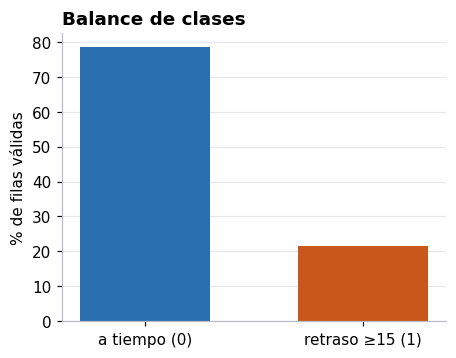

In [13]:
# 3.1 ¿Dónde es nulo el objetivo? (dataset completo)
tgt = q(f"""
    SELECT {TARGET} AS target, Cancelled, Diverted, COUNT(*) AS n
    FROM flights GROUP BY ALL ORDER BY n DESC
""")
tgt["pct"] = tgt.n / N * 100
display(tgt)

BASE_RATE = q(f"SELECT AVG({TARGET}) FROM flights").iloc[0, 0]
n_valid = q(f"SELECT COUNT({TARGET}) FROM flights").iloc[0, 0]
print(f"Filas con objetivo: {n_valid:,} ({n_valid / N:.2%}) | filas con objetivo nulo: {N - n_valid:,}")
print(f"Tasa general de retraso (objetivo = 1 entre filas válidas): {BASE_RATE:.2%}  →  desbalance ≈ 1 : {(1 - BASE_RATE) / BASE_RATE:.1f}")

fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.bar(["a tiempo (0)", "retraso ≥15 (1)"], [(1 - BASE_RATE) * 100, BASE_RATE * 100], color=[ACCENT, ALERT], width=0.6)
ax.set_title("Balance de clases"); ax.set_ylabel("% de filas válidas"); ax.grid(axis="x", visible=False)
savefig(fig, "03_class_balance")

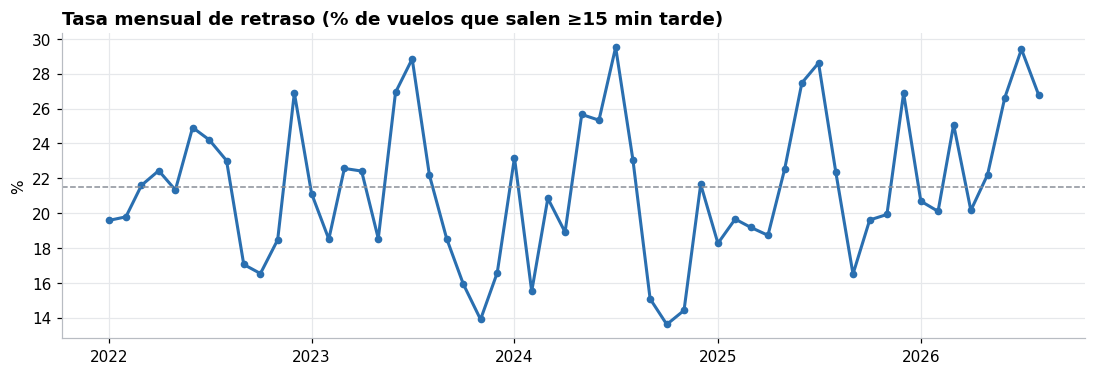

In [14]:
# 3.2 ¿Deriva la tasa de retraso en el tiempo? (importa para la división entrenamiento/prueba)
ts = q(f"""
    SELECT date_trunc('month', FlightDate)::DATE AS month, COUNT({TARGET}) AS n, AVG({TARGET}) AS delay_rate
    FROM flights GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(ts.month, ts.delay_rate * 100, color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(BASE_RATE * 100, color=MUTED, lw=1, ls="--")
ax.set_title("Tasa mensual de retraso (% de vuelos que salen ≥15 min tarde)"); ax.set_ylabel("%")
savefig(fig, "03_delay_rate_over_time")

## 4. EDA de variables previas a la salida (dataset completo)

Aquí solo se exploran variables que se conocen antes de la salida. Línea punteada = tasa general de retraso. Todos los números se calculan sobre los 32 M de filas completas dentro de DuckDB.

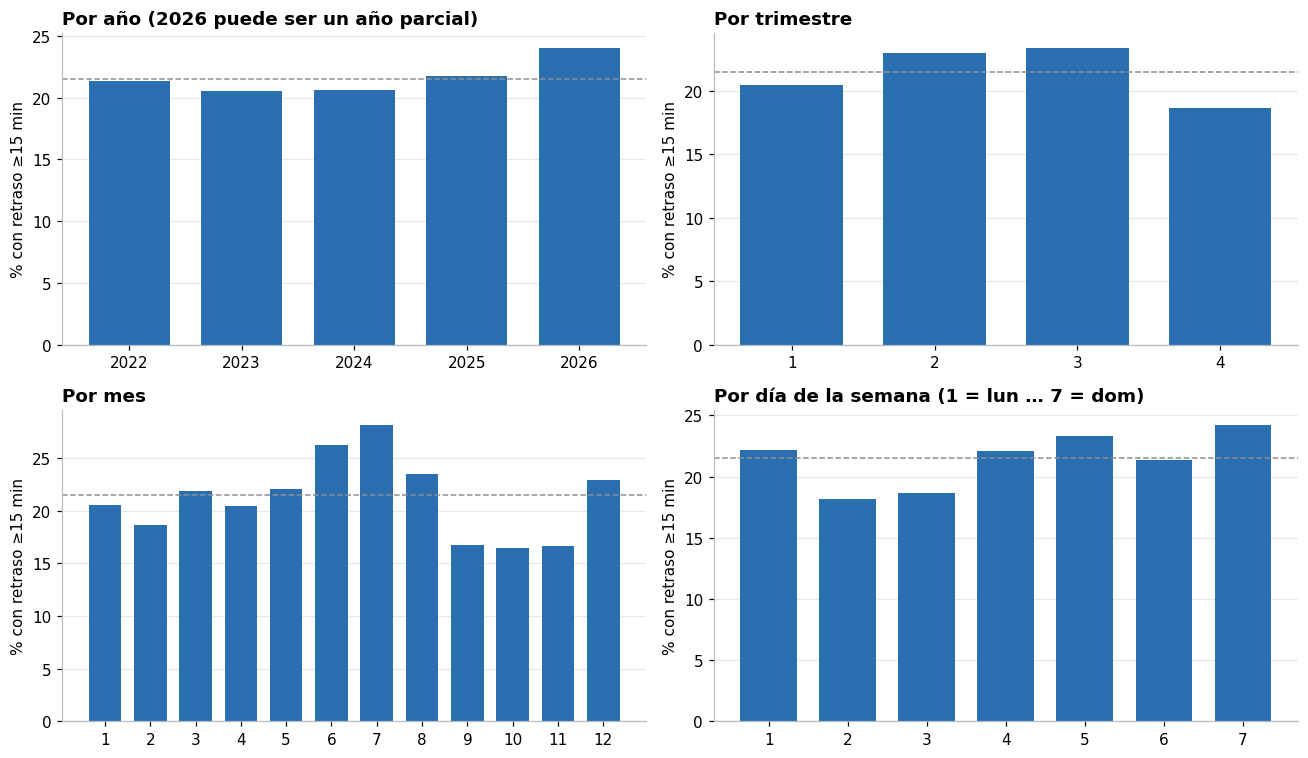

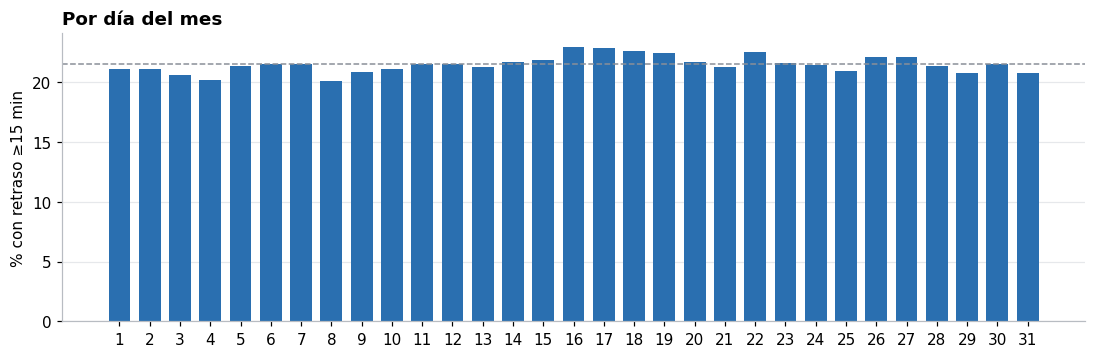

In [15]:
# 4.1 Patrones de calendario
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (expr, title) in zip(axes.ravel(), [
    ("Year", "Por año (2026 puede ser un año parcial)"),
    ("Quarter", "Por trimestre"),
    ("Month", "Por mes"),
    ("DayOfWeek", "Por día de la semana (1 = lun … 7 = dom)"),
]):
    bar_rate(rate_by(expr), ax, title)
fig.tight_layout(); savefig(fig, "04_calendar_patterns")

fig, ax = plt.subplots(figsize=(12, 3.4))
bar_rate(rate_by("DayofMonth"), ax, "Por día del mes")
savefig(fig, "04_day_of_month")

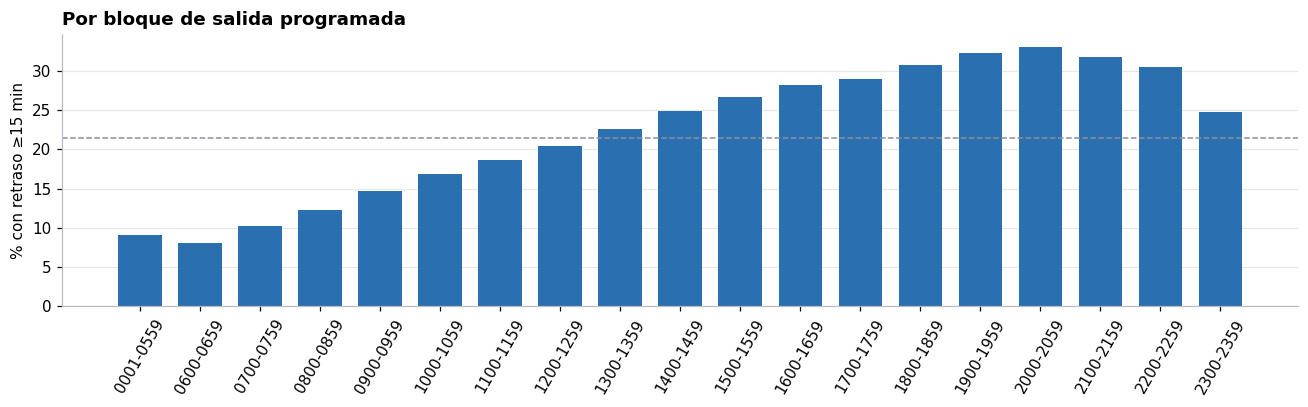

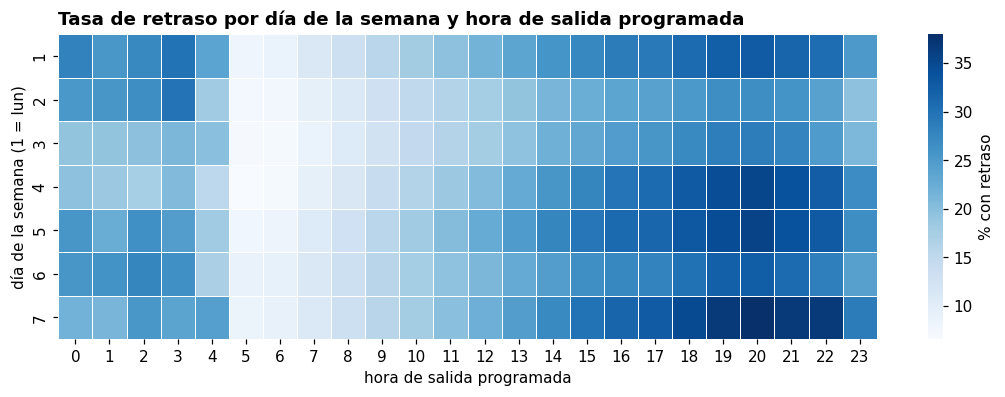

In [16]:
# 4.2 Hora programada del día: barras por bloque + mapa de calor día de la semana × hora
fig, ax = plt.subplots(figsize=(12, 3.8))
bar_rate(rate_by("DepTimeBlk"), ax, "Por bloque de salida programada", rot=60)
fig.tight_layout(); savefig(fig, "04_dep_time_block")

heat = q(f"""
    SELECT DayOfWeek AS dow, LEAST(CRSDepTime // 100, 23) AS hr, AVG({TARGET}) * 100 AS rate
    FROM flights WHERE {TARGET} IS NOT NULL GROUP BY 1, 2
""").pivot(index="dow", columns="hr", values="rate")
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "% con retraso"}, linewidths=0.5, linecolor="white")
ax.set_title("Tasa de retraso por día de la semana y hora de salida programada")
ax.set_xlabel("hora de salida programada"); ax.set_ylabel("día de la semana (1 = lun)"); ax.grid(False)
savefig(fig, "04_heatmap_dow_hour")

,airline,n,delay_rate
0,F9,868122,0.2906
1,B6,1155525,0.2890
2,WN,6396014,0.2607
3,NK,976790,0.2569
4,G4,559854,0.2473
5,AA,4356544,0.2430
6,OH,1015436,0.2093
7,YV,111050,0.1964
8,UA,3428003,0.1953
9,AS,1175147,0.1946


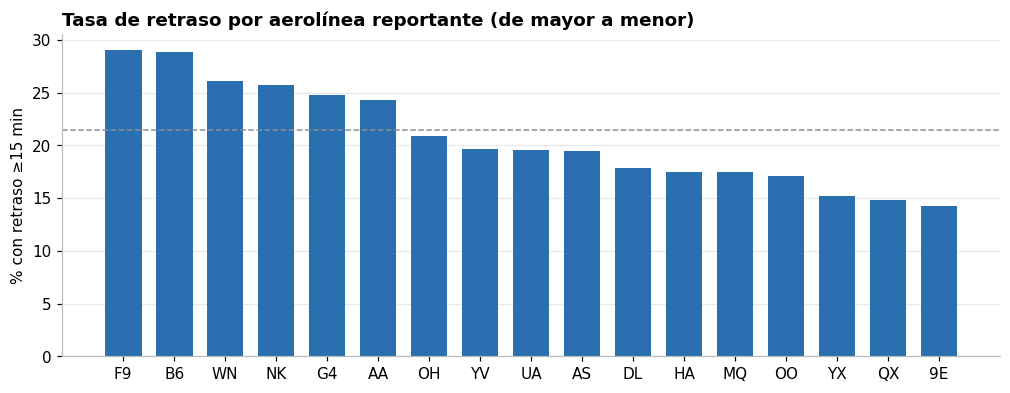

In [17]:
# 4.3 Aerolíneas
air = rate_by("Reporting_Airline", order_by="3 DESC")
display(air.rename(columns={"grp": "airline"}))
fig, ax = plt.subplots(figsize=(11, 3.8))
bar_rate(air, ax, "Tasa de retraso por aerolínea reportante (de mayor a menor)")
savefig(fig, "04_airlines")

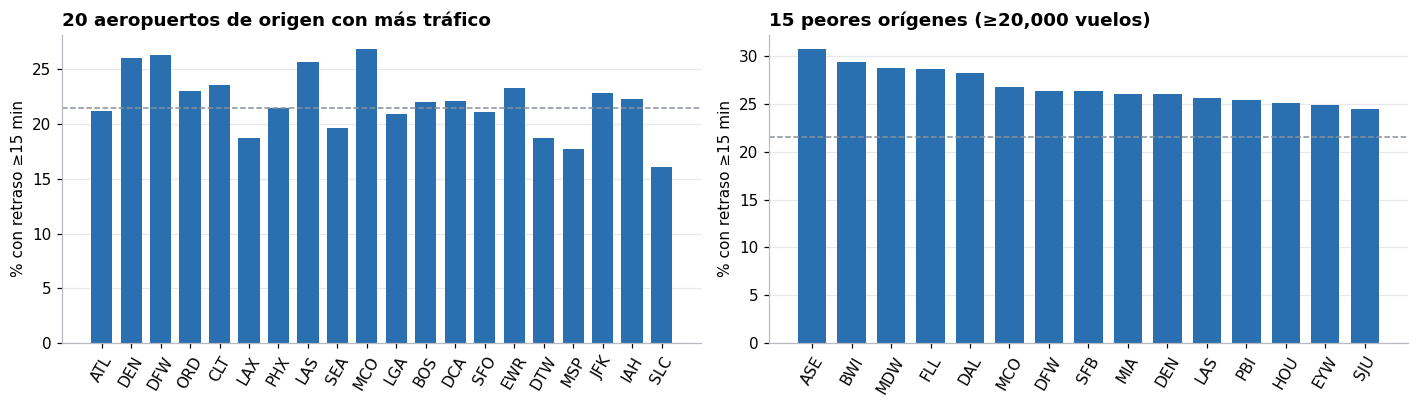

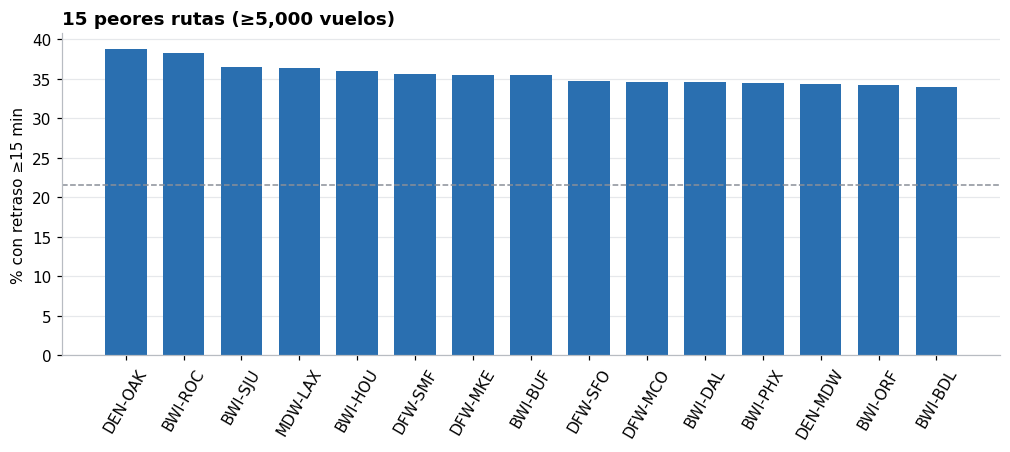

Orígenes distintos: 382 | rutas: 8255 | matrículas (tail numbers): 7312


In [18]:
# 4.4 Aeropuertos y rutas
top_orig = rate_by("Origin", order_by="2 DESC").head(20)
worst_orig = rate_by("Origin", min_n=MIN_AIRPORT_FLIGHTS, order_by="3 DESC").head(15)
worst_routes = rate_by("Origin || '-' || Dest", min_n=MIN_ROUTE_FLIGHTS, order_by="3 DESC").head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bar_rate(top_orig, axes[0], "20 aeropuertos de origen con más tráfico", rot=60)
bar_rate(worst_orig, axes[1], f"15 peores orígenes (≥{MIN_AIRPORT_FLIGHTS:,} vuelos)", rot=60)
fig.tight_layout(); savefig(fig, "04_airports")

fig, ax = plt.subplots(figsize=(11, 3.8))
bar_rate(worst_routes, ax, f"15 peores rutas (≥{MIN_ROUTE_FLIGHTS:,} vuelos)", rot=60)
savefig(fig, "04_routes")
print("Orígenes distintos:", q("SELECT COUNT(DISTINCT Origin) FROM flights").iloc[0, 0],
      "| rutas:", q("SELECT COUNT(DISTINCT Origin || '-' || Dest) FROM flights").iloc[0, 0],
      "| matrículas (tail numbers):", q("SELECT COUNT(DISTINCT Tail_Number) FROM flights").iloc[0, 0])

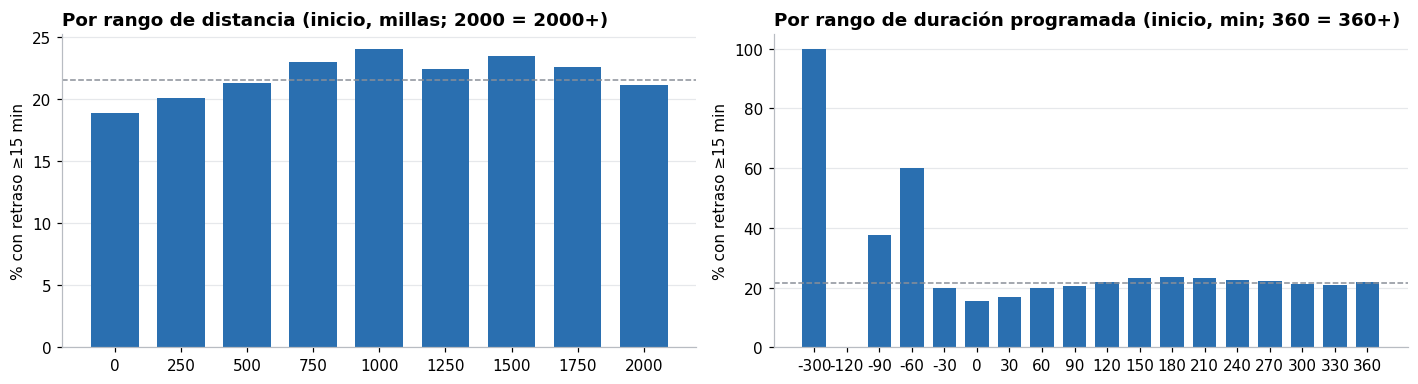

In [19]:
# 4.5 Distancia y duración programada
dist = rate_by("LEAST(FLOOR(Distance / 250), 8) * 250", where="Distance IS NOT NULL")
dur = rate_by("LEAST(FLOOR(CRSElapsedTime / 30), 12) * 30", where="CRSElapsedTime IS NOT NULL")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
bar_rate(dist.assign(grp=dist.grp.astype(int)), axes[0], "Por rango de distancia (inicio, millas; 2000 = 2000+)")
bar_rate(dur.assign(grp=dur.grp.astype(int)), axes[1], "Por rango de duración programada (inicio, min; 360 = 360+)")
fig.tight_layout(); savefig(fig, "04_distance_duration")

## 5. Muestra aleatoria para análisis a nivel de fila

Se trae a pandas una muestra reproducible de 1 M de filas (solo filas con objetivo válido). Las distribuciones, correlaciones y pruebas de fuga de más abajo usan esta muestra. Con 1 M de filas, cualquier efecto que importe en los 32 M de filas se ve con claridad.

In [20]:
df = con.sql(f"""
    SELECT * FROM (SELECT * FROM flights WHERE {TARGET} IS NOT NULL)
    USING SAMPLE reservoir({SAMPLE_ROWS} ROWS) REPEATABLE ({SEED})
""").df()
df[TARGET] = df[TARGET].astype(int)
print(f"Muestra: {df.shape[0]:,} filas × {df.shape[1]} columnas | {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB | tasa de retraso {df[TARGET].mean():.2%}")
df.describe().T

Muestra: 1,000,000 filas × 35 columnas | 610 MB | tasa de retraso 21.52%


,count,mean,min,25%,50%,75%,max,std
DepDel15,"1,000,000.0000",0.2152,0.0000,0.0000,0.0000,0.0000,1.0000,0.4110
FlightDate,1000000,2024-05-13 13:30:48.038399,2022-01-01 00:00:00,2023-03-22 00:00:00,2024-05-21 00:00:00,2025-07-09 00:00:00,2026-08-31 00:00:00,NaN
Year,"1,000,000.0000","2,023.8848","2,022.0000","2,023.0000","2,024.0000","2,025.0000","2,026.0000",1.3494
Quarter,"1,000,000.0000",2.4381,1.0000,1.0000,2.0000,3.0000,4.0000,1.0865
Month,"1,000,000.0000",6.2990,1.0000,3.0000,6.0000,9.0000,12.0000,3.3298
DayofMonth,"1,000,000.0000",15.7465,1.0000,8.0000,16.0000,23.0000,31.0000,8.7808
DayOfWeek,"1,000,000.0000",3.9909,1.0000,2.0000,4.0000,6.0000,7.0000,2.0069
CRSDepTime,"1,000,000.0000","1,326.2954",1.0000,905.0000,"1,319.0000","1,735.0000","2,359.0000",492.5066
CRSArrTime,"1,000,000.0000","1,490.0272",1.0000,"1,102.0000","1,515.0000","1,925.0000","2,359.0000",519.6994
CRSElapsedTime,"1,000,000.0000",146.9345,-272.0000,93.0000,130.0000,177.0000,706.0000,72.8917


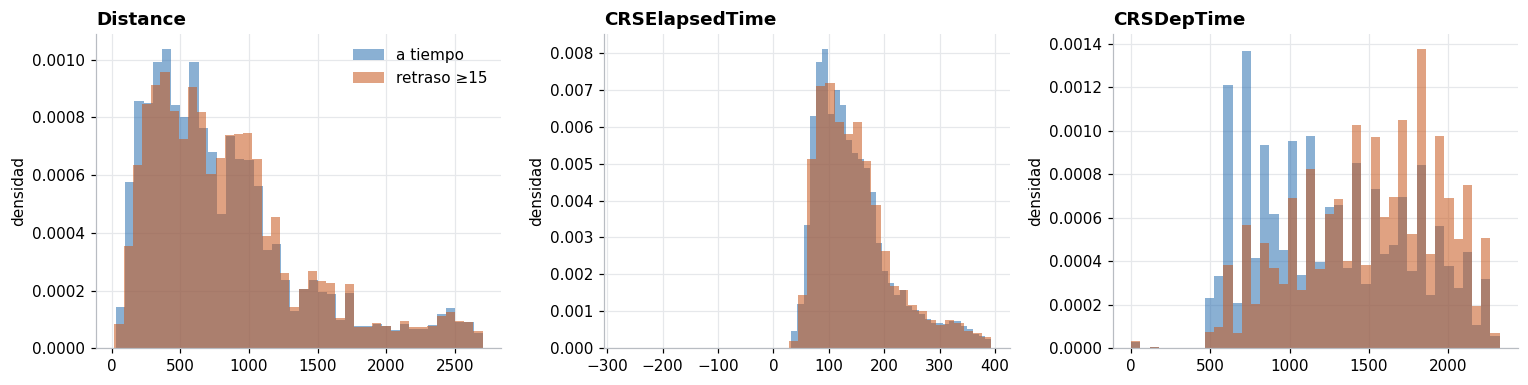

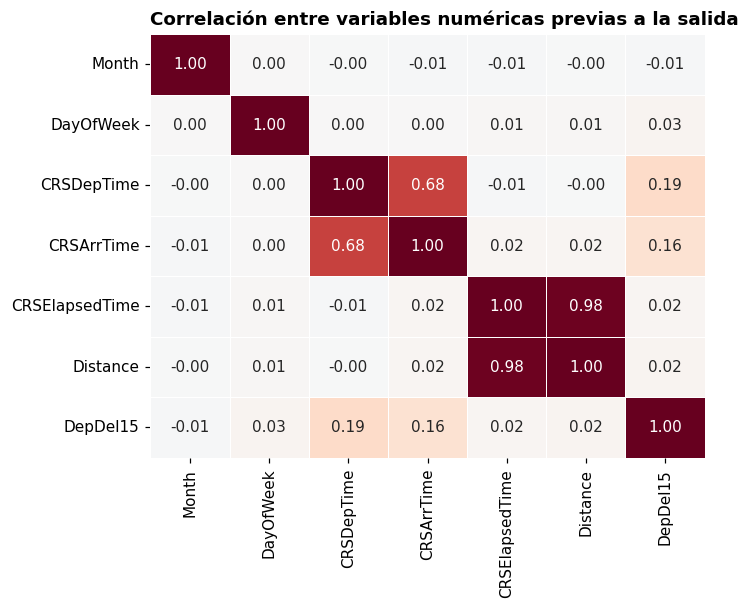

In [21]:
# 5.1 Distribuciones por clase + correlación entre variables numéricas previas a la salida
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ["Distance", "CRSElapsedTime", "CRSDepTime"]):
    hi = df[col].quantile(0.995)
    for lab, color, name in [(0, ACCENT, "a tiempo"), (1, ALERT, "retraso ≥15")]:
        vals = df.loc[(df[TARGET] == lab) & (df[col] <= hi), col].dropna()
        ax.hist(vals, bins=40, density=True, alpha=0.55, color=color, label=name)
    ax.set_title(col); ax.set_ylabel("densidad")
axes[0].legend(frameon=False)
fig.tight_layout(); savefig(fig, "05_distributions_by_class")

pre_num = ["Month", "DayOfWeek", "CRSDepTime", "CRSArrTime", "CRSElapsedTime", "Distance", TARGET]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df[pre_num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, linewidths=0.5, linecolor="white", cbar=False)
ax.set_title("Correlación entre variables numéricas previas a la salida"); ax.grid(False)
savefig(fig, "05_corr_pre_departure")

## 6. Auditoría de fuga de información

**Regla (prueba de la línea de tiempo):** una columna se permite como variable predictora solo si su valor queda fijo *en el momento de hacer la predicción o antes* (antes de la salida). La auditoría tiene tres capas:

1. **Clasificación de dominio** — cada una de las 35 columnas recibe un rol (`target` = objetivo, `feature` = variable predictora, `identifier` = identificador, `leak` = fuga) con una razón escrita.
2. **Evidencia empírica** — relaciones deterministas con el objetivo, patrones de valores faltantes y poder predictivo de cada variable por sí sola (AUC) sobre la muestra.
3. **Red de seguridad** — cualquier columna clasificada como permitida cuyo AUC individual sea sospechosamente alto se marca para revisión.

In [22]:
ROLE_TABLE = [
    # columna, rol, razón (los nombres de rol quedan en inglés porque el código los usa)
    ("DepDel15", "target", "Objetivo: 1 si el vuelo salió 15+ min después de su hora programada."),

    # ---- conocidas al momento de programar el vuelo -> permitidas
    ("FlightDate", "feature", "Fecha programada. También es la clave para una división temporal entrenamiento/prueba."),
    ("Year", "feature", "Calendario, conocido de antemano."),
    ("Quarter", "feature", "Calendario, conocido de antemano."),
    ("Month", "feature", "Calendario, conocido de antemano."),
    ("DayofMonth", "feature", "Calendario, conocido de antemano."),
    ("DayOfWeek", "feature", "Calendario, conocido de antemano."),
    ("Reporting_Airline", "feature", "Aerolínea operadora, fijada en el itinerario."),
    ("Origin", "feature", "Aeropuerto de origen programado."),
    ("Dest", "feature", "Aeropuerto de destino programado."),
    ("OriginState", "feature", "Derivada de Origin."),
    ("DestState", "feature", "Derivada de Dest."),
    ("CRSDepTime", "feature", "Hora de salida programada (CRS)."),
    ("DepTimeBlk", "feature", "Bloque horario de la salida PROGRAMADA (verificado en 6.2)."),
    ("CRSArrTime", "feature", "Hora de llegada programada (CRS)."),
    ("CRSElapsedTime", "feature", "Tiempo de bloque programado."),
    ("Distance", "feature", "Distancia ortodrómica (círculo máximo), fija según la ruta."),

    # ---- identificadores: permitidos pero de alta cardinalidad / requieren cuidado
    ("Flight_Number_Reporting_Airline", "identifier", "Conocido de antemano; cardinalidad muy alta, usar con cuidado (codificación por objetivo solo dentro del periodo de entrenamiento)."),
    ("Tail_Number", "identifier", "La aeronave suele asignarse de antemano pero puede cambiarse; alta cardinalidad. Base para variables legítimas de 'vuelo anterior de la misma aeronave' más adelante."),

    # ---- resultado del vuelo: NO se conoce antes de la salida -> fuga
    ("Cancelled", "leak", "Resultado del vuelo. El objetivo es nulo cuando vale 1; se usa para filtrar FILAS, nunca como variable predictora."),
    ("CancellationCode", "leak", "Motivo de una cancelación, registrado después."),
    ("Diverted", "leak", "Resultado que ocurre después de la salida."),
    ("DepTime", "leak", "Hora de salida REAL: DepTime - CRSDepTime es el objetivo por construcción."),
    ("DepDelay", "leak", "Retraso real de salida en minutos: DepDel15 = (DepDelay >= 15)."),
    ("DepDelayMinutes", "leak", "DepDelay con piso en 0: misma información que el objetivo."),
    ("DepartureDelayGroups", "leak", "Rangos de 15 minutos de DepDelay; grupo >= 1 es exactamente el objetivo."),
    ("TaxiOut", "leak", "Se mide después del pushback."),
    ("WheelsOff", "leak", "Hora real de despegue, posterior a la salida."),
    ("ArrDelay", "leak", "Resultado de llegada, fuertemente ligado al retraso de salida."),
    ("ArrDel15", "leak", "Resultado de llegada (retraso de llegada >= 15)."),
    ("CarrierDelay", "leak", "Desglose de causas del retraso, registrado después de los hechos."),
    ("WeatherDelay", "leak", "Desglose de causas del retraso, registrado después de los hechos."),
    ("NASDelay", "leak", "Desglose de causas del retraso, registrado después de los hechos."),
    ("SecurityDelay", "leak", "Desglose de causas del retraso, registrado después de los hechos."),
    ("LateAircraftDelay", "leak", "Desglose de causas del retraso, registrado después de los hechos."),
]
roles = pd.DataFrame(ROLE_TABLE, columns=["column", "role", "reason"])

unclassified = [c for c in ALL_COLS if c not in set(roles.column)]
not_in_data = [c for c in roles.column if c not in set(ALL_COLS)]
if unclassified:
    print("⚠ Columnas en los datos SIN rol asignado (tratadas como 'unclassified' → REVIEW):", unclassified)
    roles = pd.concat([roles, pd.DataFrame({"column": unclassified, "role": "unclassified",
                                            "reason": "No cubierta por la tabla de dominio; clasificar manualmente."})],
                      ignore_index=True)
if not_in_data:
    print("ℹ Roles definidos para columnas que no están en este archivo:", not_in_data)

roles = roles[roles.column.isin(ALL_COLS)].reset_index(drop=True)
LEAK_COLS = roles.loc[roles.role == "leak", "column"].tolist()
print(f"{roles.role.value_counts().to_dict()}")
roles

{'feature': 16, 'leak': 16, 'identifier': 2, 'target': 1}


,column,role,reason
0,DepDel15,target,Objetivo: 1 si el vuelo salió 15+ min después ...
1,FlightDate,feature,Fecha programada. También es la clave para una...
2,Year,feature,"Calendario, conocido de antemano."
3,Quarter,feature,"Calendario, conocido de antemano."
4,Month,feature,"Calendario, conocido de antemano."
5,DayofMonth,feature,"Calendario, conocido de antemano."
6,DayOfWeek,feature,"Calendario, conocido de antemano."
7,Reporting_Airline,feature,"Aerolínea operadora, fijada en el itinerario."
8,Origin,feature,Aeropuerto de origen programado.
9,Dest,feature,Aeropuerto de destino programado.


### 6.2 Evidencia empírica sobre la muestra

In [23]:
# (a) Relaciones deterministas: las columnas con fuga reproducen el objetivo
def agree(col, threshold):
    m = df[col].notna()
    return ((df.loc[m, col] >= threshold).astype(int) == df.loc[m, TARGET]).mean()

det = pd.Series({
    "(DepDelay >= 15)              == DepDel15": agree("DepDelay", 15),
    "(DepDelayMinutes >= 15)       == DepDel15": agree("DepDelayMinutes", 15),
    "(DepartureDelayGroups >= 1)   == DepDel15": agree("DepartureDelayGroups", 1),
}, name="agreement")
print("Porcentaje de filas de la muestra donde la regla reproduce exactamente el objetivo:")
display((det * 100).round(4).to_frame("concordancia_%"))

# (b) Las columnas de causa de retraso solo se llenan cuando el vuelo llegó 15+ min tarde → su nulidad filtra información
cause_cols = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]
pop = df.groupby("ArrDel15")[cause_cols].agg(lambda s: s.notna().mean())
print("\nProporción de filas donde las columnas de causa de retraso NO son nulas, según ArrDel15:")
display(pop)

# (c) DepTimeBlk: ¿es el bloque de salida PROGRAMADA o REAL?
blk_hr = pd.to_numeric(df["DepTimeBlk"].str[:2], errors="coerce")
crs_hr = (df["CRSDepTime"] // 100).clip(upper=23)
act_hr = (df["DepTime"] // 100).clip(upper=23)
m = act_hr.notna() & blk_hr.notna()
print(f"\nHora de DepTimeBlk == hora programada (CRSDepTime): {(blk_hr == crs_hr)[blk_hr.notna()].mean():.2%}")
print(f"Hora de DepTimeBlk == hora real (DepTime):       {(blk_hr[m] == act_hr[m]).mean():.2%}  (es esperable que sea menor: los vuelos retrasados cruzan los límites de hora)")

Porcentaje de filas de la muestra donde la regla reproduce exactamente el objetivo:


,concordancia_%
(DepDelay >= 15) == DepDel15,100.0000
(DepDelayMinutes >= 15) == DepDel15,100.0000
(DepartureDelayGroups >= 1) == DepDel15,100.0000



Proporción de filas donde las columnas de causa de retraso NO son nulas, según ArrDel15:


,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
ArrDel15,,,,,
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



Hora de DepTimeBlk == hora programada (CRSDepTime): 97.13%
Hora de DepTimeBlk == hora real (DepTime):       71.22%  (es esperable que sea menor: los vuelos retrasados cruzan los límites de hora)


In [24]:
# (d) Poder predictivo de cada variable por sí sola: AUC de cada columna contra el objetivo.
#     ≈0.5 = sin señal, ≈1.0 = la columna (casi) ES el objetivo.
#     Numéricas: AUC del valor crudo (NaN → mediana) y de la bandera "es faltante".
#     Categóricas / fecha: codificación por objetivo con mitades separadas (se ajusta en una mitad y se evalúa en la otra) para evitar fuga por construcción.
y = df[TARGET].values
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(df)); half = len(df) // 2
fit_idx, eval_idx = perm[:half], perm[half:]

def strength(a):
    return max(a, 1 - a)

rows = []
for c in [c for c in df.columns if c != TARGET]:
    s = df[c]
    if pd.api.types.is_numeric_dtype(s):
        if s.notna().sum() == 0:
            continue
        a_val = strength(roc_auc_score(y, s.fillna(s.median())))
        miss_flag = s.isna().astype(int)
        a_miss = strength(roc_auc_score(y, miss_flag)) if 0 < miss_flag.sum() < len(s) else 0.5
        rows.append((c, "numeric", a_val, a_miss, s.isna().mean()))
    else:
        cat = s.astype(str)
        enc = pd.Series(y[fit_idx]).groupby(cat.values[fit_idx]).mean()
        pred = pd.Series(cat.values[eval_idx]).map(enc).fillna(y[fit_idx].mean())
        rows.append((c, "categorical", strength(roc_auc_score(y[eval_idx], pred)), 0.5, s.isna().mean()))

auc_df = pd.DataFrame(rows, columns=["column", "kind", "auc_value", "auc_missingness", "pct_missing_sample"])
auc_df.sort_values("auc_value", ascending=False).head(15)

,column,kind,auc_value,auc_missingness,pct_missing_sample
22,DepDelay,numeric,1.0000,0.5000,0.0000
24,DepartureDelayGroups,numeric,1.0000,0.5000,0.0000
23,DepDelayMinutes,numeric,1.0000,0.5000,0.0000
27,ArrDelay,numeric,0.9568,0.5020,0.0032
28,ArrDel15,numeric,0.8703,0.5020,0.0032
21,DepTime,numeric,0.6737,0.5000,0.0000
26,WheelsOff,numeric,0.6696,0.5007,0.0005
12,DepTimeBlk,categorical,0.6412,0.5000,0.0000
11,CRSDepTime,numeric,0.6390,0.5000,0.0000
31,NASDelay,numeric,0.6237,0.8703,0.7851


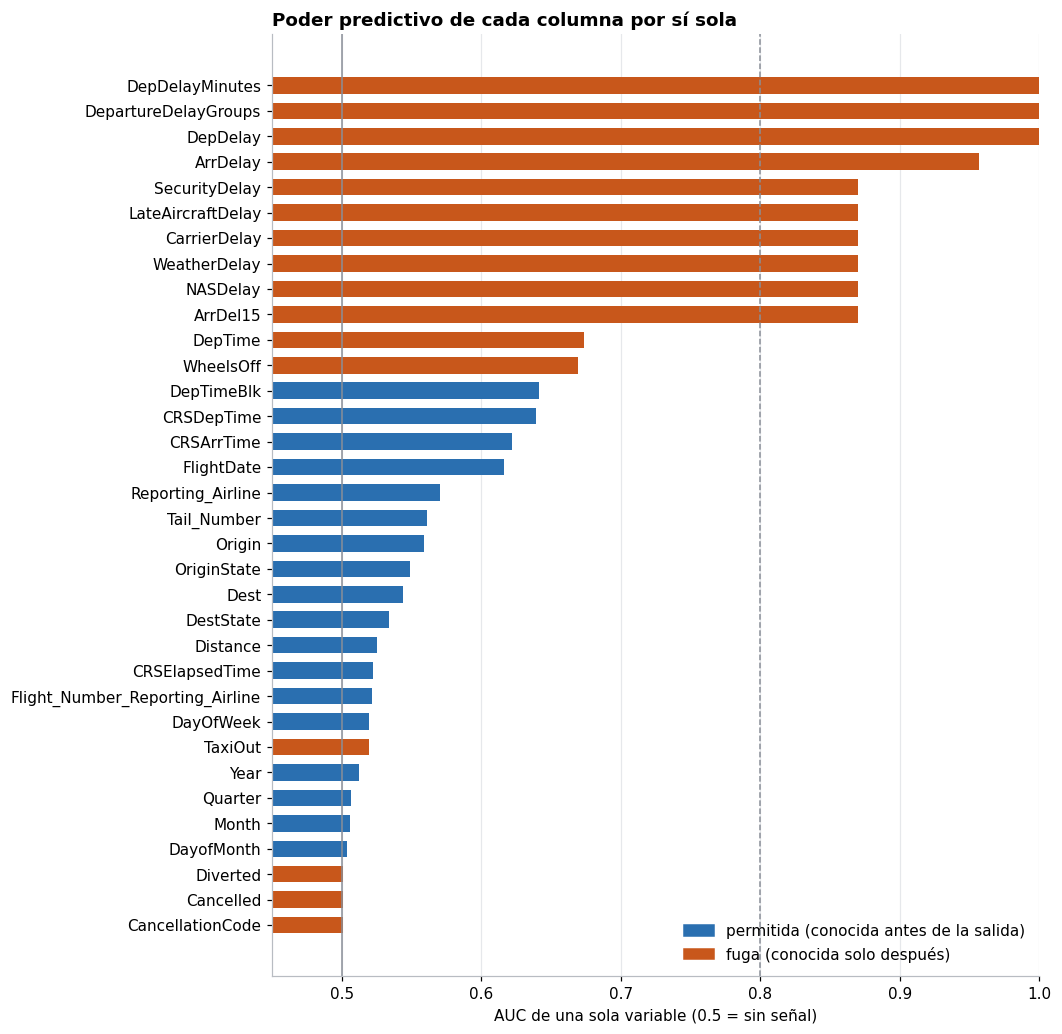

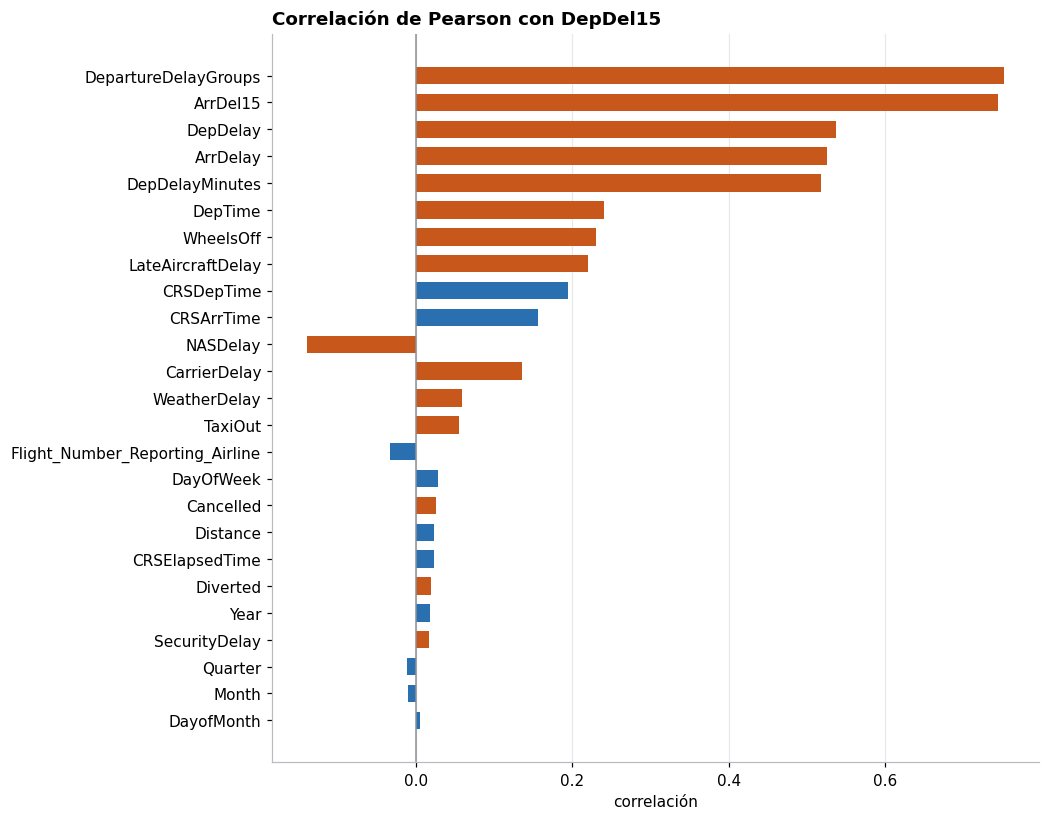

In [25]:
# Visual: las columnas con fuga resaltan de inmediato
audit = roles.merge(auc_df, on="column", how="left")
audit["strength"] = audit[["auc_value", "auc_missingness"]].max(axis=1)
role_map = roles.set_index("column")["role"]

plot_df = audit.dropna(subset=["strength"]).sort_values("strength")
colors = np.where(plot_df.role.eq("leak"), ALERT, ACCENT)
fig, ax = plt.subplots(figsize=(9, 0.28 * len(plot_df) + 1.6))
ax.barh(plot_df.column, plot_df.strength, color=colors, height=0.65)
ax.axvline(0.5, color=MUTED, lw=1)
ax.axvline(SUSPICIOUS_AUC, color=MUTED, lw=1, ls="--")
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("AUC de una sola variable (0.5 = sin señal)")
ax.set_title("Poder predictivo de cada columna por sí sola")
ax.legend(handles=[mpatches.Patch(color=ACCENT, label="permitida (conocida antes de la salida)"),
                   mpatches.Patch(color=ALERT, label="fuga (conocida solo después)")],
          frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
savefig(fig, "06_single_feature_auc")

num_cols = [c for c in df.columns if c != TARGET and pd.api.types.is_numeric_dtype(df[c])]
corr = df[num_cols].corrwith(df[TARGET]).dropna()
corr = corr.reindex(corr.abs().sort_values().index)
fig, ax = plt.subplots(figsize=(9, 0.28 * len(corr) + 1.6))
ax.barh(corr.index, corr.values, color=np.where(role_map.reindex(corr.index).eq("leak").values, ALERT, ACCENT), height=0.65)
ax.axvline(0, color=MUTED, lw=1)
ax.set_title(f"Correlación de Pearson con {TARGET}"); ax.set_xlabel("correlación")
ax.grid(axis="y", visible=False)
savefig(fig, "06_corr_with_target")

### 6.3 Tabla de decisiones

In [26]:
audit["decision"] = audit["role"].map({
    "target": "TARGET", "feature": "KEEP", "identifier": "KEEP (high-cardinality)",
    "leak": "DROP", "unclassified": "REVIEW",
})
audit["needs_review"] = audit.role.isin(["feature", "identifier", "unclassified"]) & (audit.strength > SUSPICIOUS_AUC)

order = {"DROP": 0, "REVIEW": 1, "KEEP (high-cardinality)": 2, "KEEP": 3, "TARGET": 4}
audit_view = (audit.assign(_o=audit.decision.map(order))
                    .sort_values(["_o", "strength"], ascending=[True, False])
                    .drop(columns="_o")
                    [["column", "role", "decision", "strength", "auc_value", "auc_missingness",
                      "pct_missing_sample", "needs_review", "reason"]])
display(audit_view)

flagged = audit.loc[audit.needs_review, "column"].tolist()
if flagged:
    print("⚠ Columnas permitidas con AUC individual sospechosamente alto — inspeccionar antes de usar:", flagged)
else:
    print(f"✔ Ninguna columna permitida supera el AUC {SUSPICIOUS_AUC}.")

weak_leaks = audit.loc[(audit.role == "leak") & (audit.strength < SUSPICIOUS_AUC), "column"].tolist()
print("ℹ Columnas con fuga según la línea de tiempo pero con AUC individual bajo (se eliminan igual — son posteriores a la salida):", weak_leaks)

,column,role,decision,strength,auc_value,auc_missingness,pct_missing_sample,needs_review,reason
23,DepDelay,leak,DROP,1.0000,1.0000,0.5000,0.0000,False,Retraso real de salida en minutos: DepDel15 = ...
24,DepDelayMinutes,leak,DROP,1.0000,1.0000,0.5000,0.0000,False,DepDelay con piso en 0: misma información que ...
25,DepartureDelayGroups,leak,DROP,1.0000,1.0000,0.5000,0.0000,False,Rangos de 15 minutos de DepDelay; grupo >= 1 e...
28,ArrDelay,leak,DROP,0.9568,0.9568,0.5020,0.0032,False,"Resultado de llegada, fuertemente ligado al re..."
30,CarrierDelay,leak,DROP,0.8703,0.5479,0.8703,0.7851,False,"Desglose de causas del retraso, registrado des..."
31,WeatherDelay,leak,DROP,0.8703,0.5264,0.8703,0.7851,False,"Desglose de causas del retraso, registrado des..."
32,NASDelay,leak,DROP,0.8703,0.6237,0.8703,0.7851,False,"Desglose de causas del retraso, registrado des..."
33,SecurityDelay,leak,DROP,0.8703,0.5019,0.8703,0.7851,False,"Desglose de causas del retraso, registrado des..."
34,LateAircraftDelay,leak,DROP,0.8703,0.5893,0.8703,0.7851,False,"Desglose de causas del retraso, registrado des..."
29,ArrDel15,leak,DROP,0.8703,0.8703,0.5020,0.0032,False,Resultado de llegada (retraso de llegada >= 15).


✔ Ninguna columna permitida supera el AUC 0.8.
ℹ Columnas con fuga según la línea de tiempo pero con AUC individual bajo (se eliminan igual — son posteriores a la salida): ['Cancelled', 'CancellationCode', 'Diverted', 'DepTime', 'TaxiOut', 'WheelsOff']


### 6.4 Riesgos de fuga más sutiles a tener en cuenta (no se eliminan quitando columnas)

- **División aleatoria entrenamiento/prueba.** Las tasas de retraso derivan con el tiempo (sección 3.2). Divide **por fecha** (p. ej. entrenamiento 2022–2024, validación 2025, prueba 2026), nunca al azar.
- **Codificación por objetivo / por frecuencia** de `Origin`, `Dest`, ruta, aerolínea o `Tail_Number` debe ajustarse solo con el periodo de entrenamiento.
- **Variables móviles o de "vuelo anterior"** (p. ej. el retraso del tramo previo de la misma aeronave) son legítimas solo si ese tramo **ya había aterrizado** antes de la salida programada de este vuelo; de lo contrario usan el futuro.
- **Clima y otras fuentes unidas** deben ser el pronóstico/observación disponible *antes* de la salida, no el valor en el momento de la salida o después.
- **`Cancelled` / `Diverted`** son resultados. Las filas canceladas desaparecen porque su objetivo es nulo; los vuelos desviados sí salieron, así que se mantienen salvo que `DROP_DIVERTED_ROWS = True` (decisión del equipo).
- **Duplicados** entre las particiones pueden inflar los puntajes; la verificación 2.3 reporta cuántos existen.

## 7. Filtrado y exportación

Filtro de columnas: conservar `target` + `feature` + `identifier`; eliminar toda columna `leak`. Filtro de filas: eliminar las filas con objetivo nulo (canceladas / sin reporte). El archivo se escribe con un `COPY` en streaming, y las columnas de enteros pequeños se convierten a tipos más angostos para reducir el tamaño.

In [27]:
KEEP_ROLES = {"target", "feature", "identifier"}
keep_set = set(roles.loc[roles.role.isin(KEEP_ROLES), "column"])
KEEP_COLS = [c for c in ALL_COLS if c in keep_set]          # conserva el orden original de columnas
DROPPED_COLS = [c for c in ALL_COLS if c not in keep_set]

CAST_MAP = {
    TARGET: "TINYINT", "Year": "SMALLINT", "Quarter": "TINYINT", "Month": "TINYINT",
    "DayofMonth": "TINYINT", "DayOfWeek": "TINYINT", "CRSDepTime": "SMALLINT",
    "CRSArrTime": "SMALLINT", "Flight_Number_Reporting_Airline": "INTEGER",
}
select_list = ", ".join(f'CAST("{c}" AS {CAST_MAP[c]}) AS "{c}"' if c in CAST_MAP else f'"{c}"' for c in KEEP_COLS)
row_filter = f"{TARGET} IS NOT NULL" + (" AND COALESCE(Diverted, 0) = 0" if DROP_DIVERTED_ROWS else "")

OUT_PARQUET = OUT_DIR / "flights_clean_no_leakage.parquet"
con.execute(f"""
    COPY (SELECT {select_list} FROM flights WHERE {row_filter})
    TO '{OUT_PARQUET}' (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 1000000)
""")
print(f"Se conservaron {len(KEEP_COLS)} columnas, se eliminaron {len(DROPPED_COLS)}:\n  eliminadas = {DROPPED_COLS}")
print(f"Escrito: {OUT_PARQUET}  ({OUT_PARQUET.stat().st_size / 1e9:.2f} GB)")

Se conservaron 19 columnas, se eliminaron 16:
  eliminadas = ['Cancelled', 'CancellationCode', 'Diverted', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepartureDelayGroups', 'TaxiOut', 'WheelsOff', 'ArrDelay', 'ArrDel15', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
Escrito: outputs_eda\flights_clean_no_leakage.parquet  (0.21 GB)


In [32]:
# Verificar el archivo exportado
clean = f"read_parquet('{OUT_PARQUET}')"
n_clean = con.execute(f"SELECT COUNT(*) FROM {clean}").fetchall()[0][0]
clean_schema = con.sql(f"DESCRIBE SELECT * FROM {clean}").df()[["column_name", "column_type"]]
null_target = con.execute(f"SELECT COUNT(*) - COUNT({TARGET}) FROM {clean}").fetchall()[0][0]

assert not (set(clean_schema.column_name) & set(LEAK_COLS)), "¡Todavía hay columnas con fuga en el archivo limpio!"
assert null_target == 0, "¡El archivo limpio todavía tiene objetivos nulos!"
print(f"✔ Sin columnas con fuga, sin objetivos nulos. Filas: {n_clean:,} (eliminadas {N - n_clean:,} = {(N - n_clean) / N:.2%})")

by_year = con.sql(f"""
    SELECT Year, COUNT(*) AS n, AVG({TARGET}) AS delay_rate FROM {clean} GROUP BY 1 ORDER BY 1
""").df()
display(clean_schema, by_year)

# Guardar la auditoría para poder pegarla en el documento de "descripción de datos"
audit_view.to_csv(OUT_DIR / "leakage_audit.csv", index=False)
with open(OUT_DIR / "columns_summary.json", "w") as f:
    json.dump({"kept": KEEP_COLS, "dropped_as_leakage": DROPPED_COLS, "target": TARGET,
               "rows_before": int(N), "rows_after": int(n_clean)}, f, indent=2)

✔ Sin columnas con fuga, sin objetivos nulos. Filas: 31,833,031 (eliminadas 553,405 = 1.71%)


,column_name,column_type
0,DepDel15,TINYINT
1,FlightDate,DATE
2,Year,SMALLINT
3,Reporting_Airline,VARCHAR
4,Quarter,TINYINT
5,Month,TINYINT
6,DayofMonth,TINYINT
7,DayOfWeek,TINYINT
8,Origin,VARCHAR
9,Dest,VARCHAR


,Year,n,delay_rate
0,2022,6551777,0.2134
1,2023,6763370,0.2053
2,2024,6986091,0.2066
3,2025,6903028,0.2176
4,2026,4628765,0.2403


In [33]:
# Resumen para el equipo
print("=" * 70)
print(f"Filas: {N:,} → {n_clean:,} tras eliminar las filas con objetivo nulo")
print(f"Tasa general de retraso: {BASE_RATE:.2%}  (desbalance ≈ 1 : {(1 - BASE_RATE) / BASE_RATE:.1f})")
print(f"Columnas: {len(ALL_COLS)} → {len(KEEP_COLS)}  (objetivo + {len(KEEP_COLS) - 1} variables candidatas)")
print(f"Eliminadas por fuga ({len(DROPPED_COLS)}): {', '.join(DROPPED_COLS)}")
print(f"Columnas permitidas marcadas como sospechosas (AUC > {SUSPICIOUS_AUC}): {flagged or 'ninguna'}")
print(f"Salidas en: {OUT_DIR.resolve()}")
print("=" * 70)

Filas: 32,386,436 → 31,833,031 tras eliminar las filas con objetivo nulo
Tasa general de retraso: 21.50%  (desbalance ≈ 1 : 3.7)
Columnas: 35 → 19  (objetivo + 18 variables candidatas)
Eliminadas por fuga (16): Cancelled, CancellationCode, Diverted, DepTime, DepDelay, DepDelayMinutes, DepartureDelayGroups, TaxiOut, WheelsOff, ArrDelay, ArrDel15, CarrierDelay, WeatherDelay, NASDelay, SecurityDelay, LateAircraftDelay
Columnas permitidas marcadas como sospechosas (AUC > 0.8): ninguna
Salidas en: C:\Users\uplev\Downloads\pintegrador\outputs_eda
